# Trabajo Práctico — Análisis de un Dataset

## Fundamentos de Aprendizaje Automático · 2026

**Docente:** Prof. Ramón F. López-Imizcoz

**Modalidad:** individual o en equipo (se sugiere no más de 2 integrantes)

**Entrega:** este mismo notebook de Google Colab, completado y ejecutado.

---

### Objetivo

El objetivo de este trabajo es **simple pero completo**: elegir un dataset, identificar correctamente el **tipo de datos** que contiene, aplicar las **herramientas de análisis adecuadas** para ese tipo de datos, y razonar sobre **qué modelo** se podría construir y **para qué uso** concreto.

No se busca aquí entrenar un modelo complejo ni alcanzar una métrica óptima. Se busca que demuestren que entienden el **flujo de razonamiento** que va desde los datos hasta una decisión de modelado fundamentada.

> **Sugerencia de uso:** ejecuten celda por celda. Antes de ejecutar una celda de código, pregúntense *"¿qué espero ver como salida?"* y recién después comparen con el resultado real.


# 1. Consigna

A lo largo de este notebook deberán completar las siguientes **cinco etapas**:

1. **Elección del dataset.** Seleccionar un conjunto de datos y justificar brevemente por qué les interesa.
2. **Identificación del tipo de datos.** Determinar qué tipo de variables contiene (numéricas, categóricas, temporales, texto, etc.) y si hay o no una variable objetivo (*target*).
3. **Análisis exploratorio (EDA).** Aplicar las herramientas de análisis **adecuadas al tipo de datos** identificado: estadísticos descriptivos, visualizaciones, correlaciones, conteos, etc.
4. **Propuesta de modelo.** Indicar qué **tipo de modelo** se podría construir (clasificación, regresión, agrupamiento/*clustering*, etc.) y por qué ese tipo es el correcto para estos datos.
5. **Uso previsto.** Explicar **para qué** y **para quién** se construiría ese modelo: qué decisión ayudaría a tomar y en qué contexto.

Cada etapa tiene su propia sección más abajo, con celdas de texto para sus respuestas y celdas de código para el análisis.


# 2. Recordatorio: tipos de datos y herramientas asociadas

Antes de empezar, conviene recordar la relación entre el **tipo de dato** y la **herramienta de análisis** apropiada. Esta tabla es su brújula durante el trabajo:

| Tipo de variable | Ejemplos | Análisis exploratorio típico | Modelos asociados |
|---|---|---|---|
| **Numérica continua** | precio, edad, temperatura | histograma, media/mediana/desvío, correlación | regresión, clustering |
| **Numérica discreta** | cantidad de hijos, n.º de visitas | conteos, histograma | regresión, clasificación |
| **Categórica nominal** | país, color, marca | tabla de frecuencias, gráfico de barras | clasificación |
| **Categórica ordinal** | nivel educativo, satisfacción (bajo/medio/alto) | barras, conteos ordenados | clasificación, regresión ordinal |
| **Temporal** | fecha, hora, timestamp | serie temporal, tendencia/estacionalidad | series de tiempo, forecasting |
| **Texto** | reseñas, comentarios | longitud, palabras frecuentes | NLP, clasificación de texto |

> **Idea clave:** la herramienta de análisis **no se elige al azar**: se deriva del tipo de dato. Un histograma tiene sentido para una variable numérica; una tabla de frecuencias, para una categórica.


# 3. Preparación del entorno

Ejecuten esta celda primero. Importa las librerías estándar que usaremos: `pandas` para manipular tablas, `numpy` para cálculo numérico, y `matplotlib`/`seaborn` para visualizar.


In [1]:
# Importamos las librerías de trabajo
import pandas as pd          # manipulación de datos en tablas (DataFrames)
import numpy as np           # cálculo numérico
import matplotlib.pyplot as plt  # gráficos
import seaborn as sns        # gráficos estadísticos de alto nivel

# Configuración estética de los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 4)

print("Entorno listo. Versiones:")
print("pandas :", pd.__version__)
print("numpy  :", np.__version__)


Entorno listo. Versiones:
pandas : 3.1.1
numpy  : 2.5.5


# Etapa 1 — Elección del dataset

Elijan **un** dataset. Tienen tres caminos posibles:

**Opción A — Dataset incorporado en seaborn (lo más simple).**
Por ejemplo: `tips`, `titanic`, `penguins`, `iris`, `diamonds`, `flights`.

**Opción B — Subir un archivo CSV propio.**
Usen el panel de archivos de Colab (ícono de carpeta a la izquierda) o la celda de carga de más abajo.

**Opción C — Desde una URL pública** (un CSV accesible por internet).

Completen la celda de código según la opción elegida. Dejen **descomentada solo una** de las tres opciones.


In [2]:
# === Opción A: dataset incorporado en seaborn ===
# df = sns.load_dataset("penguins")

# === Opción B (elegida): CSV propio ===
# Se busca primero la ruta local (ejecución desde la raíz del repositorio).
# Si el archivo no está y el notebook corre en Google Colab, se ofrece subirlo.
from pathlib import Path

ruta_csv = Path("data/store-service-request-count-per-target-hourly-since-2026-05-01.csv")

if not ruta_csv.exists():
    try:
        from google.colab import files   # solo existe en Colab
        subido = files.upload()          # abre el diálogo de carga
        ruta_csv = Path(list(subido.keys())[0])
    except ImportError:
        raise FileNotFoundError(f"No se encontró el CSV en {ruta_csv.resolve()}. "
                                "Ejecuten el notebook desde la raíz del repositorio.")

columnas_fecha = ["period_start_utc", "period_end_utc"]
df = pd.read_csv(ruta_csv, parse_dates=columnas_fecha)
for col in columnas_fecha:
    df[col] = pd.to_datetime(df[col], utc=True)   # los timestamps vienen en UTC (sufijo Z)

# === Opción C: leer un CSV desde una URL pública ===
# url = "https://ejemplo.com/mi_dataset.csv"
# df = pd.read_csv(url)

# Vistazo inicial
print("Archivo:", ruta_csv.name)
df.head()

Archivo: store-service-request-count-per-target-hourly-since-2026-05-01.csv


,load_balancer,target_group,metric_name,period_start_utc,period_end_utc,value
0,app/bodegaai-production-alb/31b69d3d76ab5ed1,targetgroup/bodegaai-production-store-servic/7...,RequestCountPerTarget,2026-05-01 00:00:00+00:00,2026-05-01 01:00:00+00:00,0.0
1,app/bodegaai-production-alb/31b69d3d76ab5ed1,targetgroup/bodegaai-production-store-servic/7...,RequestCountPerTarget,2026-05-01 01:00:00+00:00,2026-05-01 02:00:00+00:00,0.0
2,app/bodegaai-production-alb/31b69d3d76ab5ed1,targetgroup/bodegaai-production-store-servic/7...,RequestCountPerTarget,2026-05-01 02:00:00+00:00,2026-05-01 03:00:00+00:00,0.0
3,app/bodegaai-production-alb/31b69d3d76ab5ed1,targetgroup/bodegaai-production-store-servic/7...,RequestCountPerTarget,2026-05-01 03:00:00+00:00,2026-05-01 04:00:00+00:00,0.0
4,app/bodegaai-production-alb/31b69d3d76ab5ed1,targetgroup/bodegaai-production-store-servic/7...,RequestCountPerTarget,2026-05-01 04:00:00+00:00,2026-05-01 05:00:00+00:00,0.0


### ✏️ Su respuesta — Etapa 1

**Dataset elegido:** `store-service-request-count-per-target-hourly-since-2026-05-01.csv` (carpeta `data/` del repositorio). Es la métrica de AWS CloudWatch **`RequestCountPerTarget`** del *Application Load Balancer* de producción (`bodegaai-production-alb`) para el *target group* del servicio de tienda (*store service*), exportada a CSV con granularidad **horaria**.

**¿Por qué lo eligieron?** Son datos reales de operación de un sistema en producción, no un dataset de ejemplo: 3575 horas consecutivas, del 01/05/2026 al 26/09/2026, con la cantidad promedio de solicitudes que recibe cada *target* del servicio. Representa la **demanda** sobre el servicio a lo largo del tiempo. Permite practicar análisis de series temporales y responder una pregunta con valor práctico: ¿se puede anticipar la carga para dimensionar la infraestructura?

**Definición de la métrica (AWS):** `RequestCountPerTarget` se calcula sobre un *target group* (dimensión `TargetGroup`). Su valor es *"the total number of requests received by the target group, divided by the number of healthy targets in the target group"*, es decir, el total de solicitudes del grupo dividido por la cantidad de **targets sanos**. Un *target* es cada instancia EC2, tarea ECS o IP registrada en el *target group*. Fuente: [CloudWatch metrics for your Application Load Balancer](https://docs.aws.amazon.com/elasticloadbalancing/latest/application/load-balancer-cloudwatch-metrics.html).

# Etapa 2 — Identificación del tipo de datos

Ahora vamos a inspeccionar la estructura del dataset para entender **qué tipo de variables** contiene.


In [3]:
# Dimensiones del dataset: (filas, columnas)
print("Filas y columnas:", df.shape)
print()

# Tipo de dato que pandas asignó a cada columna
print("Tipos de cada columna:")
print(df.dtypes)


Filas y columnas: (3575, 6)

Tipos de cada columna:
load_balancer                       str
target_group                        str
metric_name                         str
period_start_utc    datetime64[us, UTC]
period_end_utc      datetime64[us, UTC]
value                           float64
dtype: object


In [4]:
# Resumen general: tipos, valores no nulos y memoria
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 3575 entries, 0 to 3574
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype              
---  ------            --------------  -----              
 0   load_balancer     3575 non-null   str                
 1   target_group      3575 non-null   str                
 2   metric_name       3575 non-null   str                
 3   period_start_utc  3575 non-null   datetime64[us, UTC]
 4   period_end_utc    3575 non-null   datetime64[us, UTC]
 5   value             3575 non-null   float64            
dtypes: datetime64[us, UTC](2), float64(1), str(3)
memory usage: 167.7 KB


In [5]:
# ¿Cuántos valores faltantes (NaN) hay por columna?
print("Valores faltantes por columna:")
print(df.isna().sum())


Valores faltantes por columna:
load_balancer       0
target_group        0
metric_name         0
period_start_utc    0
period_end_utc      0
value               0
dtype: int64


In [6]:
# Diagnóstico específico de una serie temporal
# 1) ¿Cuántos valores distintos tiene cada columna? (detecta columnas constantes)
print("Valores únicos por columna:")
print(df.nunique())
print()

# 2) Filas duplicadas y duración de cada período
print("Filas duplicadas:", df.duplicated().sum())
print("Duraciones de período encontradas:", (df["period_end_utc"] - df["period_start_utc"]).unique().tolist())
print()

# 3) ¿La grilla horaria está completa? Comparamos contra un rango horario sin huecos
serie = df.set_index("period_start_utc")["value"].sort_index()
rango_completo = pd.date_range(serie.index.min(), serie.index.max(), freq="h")
print("Desde:", serie.index.min(), "| Hasta:", serie.index.max())
print("Horas esperadas:", len(rango_completo), "| Horas presentes:", len(serie))
print("Horas faltantes:", len(rango_completo.difference(serie.index)),
      "| Timestamps duplicados:", serie.index.duplicated().sum())
print()

# 4) Horas con valor 0: antes y después de la primera hora con tráfico
primera_hora_activa = serie[serie > 0].index.min()
antes = serie[serie.index < primera_hora_activa]
despues = serie[serie.index >= primera_hora_activa]
ceros_despues = despues[despues == 0]
print("Primera hora con tráfico:", primera_hora_activa)
print("Horas en 0 antes de esa hora:", (antes == 0).sum(), "de", len(antes))
print("Horas en 0 después de esa hora:", len(ceros_despues),
      f"(entre {ceros_despues.index.min():%Y-%m-%d} y {ceros_despues.index.max():%Y-%m-%d})")
print("Valores no enteros en 'value':", (df["value"] % 1 != 0).sum())

Valores únicos por columna:
load_balancer          1
target_group           1
metric_name            1
period_start_utc    3575
period_end_utc      3575
value               2219
dtype: int64

Filas duplicadas: 0
Duraciones de período encontradas: [Timedelta('0 days 01:00:00')]

Desde: 2026-05-01 00:00:00+00:00 | Hasta: 2026-09-26 22:00:00+00:00
Horas esperadas: 3575 | Horas presentes: 3575
Horas faltantes: 0 | Timestamps duplicados: 0

Primera hora con tráfico: 2026-06-22 16:00:00+00:00
Horas en 0 antes de esa hora: 1264 de 1264
Horas en 0 después de esa hora: 61 (entre 2026-06-22 y 2026-06-26)
Valores no enteros en 'value': 1131


### ¿Qué observar?

- ¿Qué columnas son **numéricas** (`int64`, `float64`) y cuáles **categóricas** (`object`, `category`)?
- ¿Hay alguna columna que represente una **fecha** o un **texto libre**?
- ¿Hay valores faltantes? ¿En qué columnas y en qué proporción?
- ¿Cuál de las columnas podría ser una **variable objetivo (target)** —algo que querríamos predecir— y cuáles serían **features** (variables de entrada)?


### ✏️ Su respuesta — Etapa 2

**Tipos de variables encontradas:**

| Columna | Tipo pandas | Clasificación | Observación |
|---|---|---|---|
| `load_balancer` | texto | Categórica nominal | **Constante** (1 único valor): no aporta información |
| `target_group` | texto | Categórica nominal | **Constante** (1 único valor) |
| `metric_name` | texto | Categórica nominal | **Constante** (`RequestCountPerTarget`) |
| `period_start_utc` | `datetime64[UTC]` | **Temporal** | Inicio de cada hora; es el índice natural de la serie |
| `period_end_utc` | `datetime64[UTC]` | Temporal | **Redundante**: siempre es `period_start_utc` + 1 hora |
| `value` | `float64` | **Numérica continua** | Solicitudes del *target group* en la hora ÷ targets sanos (definición de AWS). Aparecen valores con `.5` (1131 filas) porque es un cociente, no un conteo entero |

En la práctica, el dataset es una **serie temporal univariada**: una sola variable numérica (`value`) medida cada hora. No hay texto libre.

**¿Hay una variable objetivo (target)?** Sí, pero no como una columna de etiqueta. Lo que interesa predecir es **`value` en las horas futuras**, a partir de su propio historial y del calendario (hora del día, día de la semana). Las columnas constantes no pueden ser *features*.

**Calidad de los datos:**
- **0 valores faltantes** y **0 filas duplicadas**.
- **Grilla horaria completa:** 3575 horas esperadas y 3575 presentes, entre el 01/05/2026 00:00 y el 26/09/2026 22:00 UTC, sin huecos.
- **Ceros con significado distinto:**
  - **1264 horas en 0 antes del 22/06/2026 16:00 UTC**. El servicio todavía no recibía tráfico, así que no son faltantes sino un período **previo a la puesta en producción**.
  - **61 horas en 0 entre el 22 y el 26 de junio**: es la semana de puesta en marcha, con tráfico intermitente.
  - Ambos tramos se tratan aparte en el EDA, porque mezclarlos con la operación normal distorsionaría la media y la distribución.

# Etapa 3 — Análisis exploratorio (EDA)

Apliquen las herramientas **adecuadas al tipo de datos** que identificaron en la etapa anterior. Abajo hay celdas de plantilla para los casos más comunes. **Usen y adapten las que correspondan** a su dataset; borren o ignoren las que no apliquen.


### 3.0 — Segmentación de la serie (paso previo)

En la Etapa 2 vimos que la serie tiene tramos con significados distintos: un período **sin tráfico** (el servicio aún no estaba en producción), una **puesta en marcha** con ceros intermitentes y crecimiento rápido, y una **operación estable**. Si se mezclan, las estadísticas quedan distorsionadas: la media baja y aparece una cola artificial de valores bajos.

**Criterio para el inicio del período estable:** el primer lunes cuya media semanal alcance el **90 % de la mediana** de las medias semanales del período activo. La mediana no se ve arrastrada por las semanas de arranque. La tabla semanal se imprime completa para que el corte se pueda verificar.

Medias semanales del período activo (semana que empieza el lunes):
period_start_utc
2026-06-22 00:00:00+00:00     16188.0
2026-06-29 00:00:00+00:00     62934.0
2026-07-06 00:00:00+00:00     89172.0
2026-07-13 00:00:00+00:00     98323.0
2026-07-20 00:00:00+00:00     99050.0
2026-07-27 00:00:00+00:00     98046.0
2026-08-03 00:00:00+00:00     97368.0
2026-08-10 00:00:00+00:00    103192.0
2026-08-17 00:00:00+00:00    110661.0
2026-08-24 00:00:00+00:00    114829.0
2026-08-31 00:00:00+00:00    119066.0
2026-09-07 00:00:00+00:00    116429.0
2026-09-14 00:00:00+00:00    106085.0
2026-09-21 00:00:00+00:00    104515.0
Freq: W-MON

Mediana semanal: 101,121  ->  umbral (90 %): 91,009
Inicio del período activo : 2026-06-22 16:00:00+00:00
Inicio del período estable: 2026-07-13 00:00:00+00:00
Horas: sin tráfico=1264, puesta en marcha=488, estable=1823


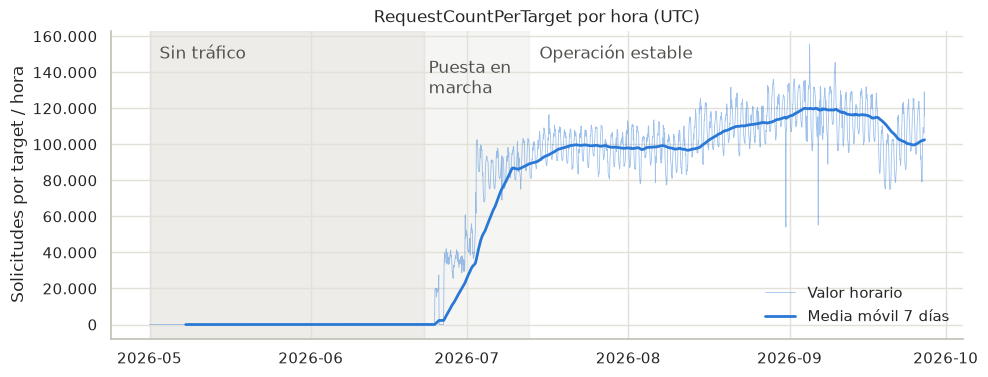

In [7]:
# Estilo de gráficos: grilla tenue, un solo color para la serie
AZUL = "#2a78d6"     # color de la serie
TINTA = "#52514e"    # líneas de referencia y textos secundarios
plt.rcParams.update({"axes.edgecolor": "#c3c2b7", "grid.color": "#e1e0d9",
                     "axes.spines.top": False, "axes.spines.right": False})

# Formato de números en convención española: punto para miles, coma para decimales
from matplotlib.ticker import FuncFormatter

def numero_es(x, decimales=0):
    texto = f"{x:,.{decimales}f}"                                        # formato inglés: 1,234.5
    return texto.replace(",", "_").replace(".", ",").replace("_", ".")  # convención española: 1.234,5

EJE_ES = FuncFormatter(lambda x, pos: numero_es(x, 0 if float(x).is_integer() else 1))
EJE_MILLONES = FuncFormatter(lambda x, pos: numero_es(x / 1e6, 1) + " M")
FORMATO_VALOR = EJE_ES   # los valores de esta serie no llegan al millón

def valor_es(x):
    return numero_es(x)

# Serie indexada por tiempo (definida también en la Etapa 2; se recalcula para que la sección sea autocontenida)
serie = df.set_index("period_start_utc")["value"].sort_index()
inicio_activo = serie[serie > 0].index.min()
activa = serie[serie.index >= inicio_activo]

# Medias semanales (semanas de lunes a domingo) del período activo
semanal = activa.resample("W-MON", label="left", closed="left").mean()
umbral = 0.9 * semanal.median()
inicio_estable = semanal[semanal >= umbral].index.min()
estable = serie[serie.index >= inicio_estable]

print("Medias semanales del período activo (semana que empieza el lunes):")
print(semanal.round(0).to_string())
print(f"\nMediana semanal: {semanal.median():,.0f}  ->  umbral (90 %): {umbral:,.0f}")
print("Inicio del período activo :", inicio_activo)
print("Inicio del período estable:", inicio_estable)
print(f"Horas: sin tráfico={len(serie[serie.index < inicio_activo])}, "
      f"puesta en marcha={len(activa[activa.index < inicio_estable])}, estable={len(estable)}")

# Serie completa con los períodos sombreados y media móvil de 7 días
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(serie.index, serie, color=AZUL, linewidth=0.6, alpha=0.45, label="Valor horario")
ax.plot(serie.index, serie.rolling(24 * 7).mean(), color=AZUL, linewidth=2, label="Media móvil 7 días")
ax.axvspan(serie.index.min(), inicio_activo, color="#e1e0d9", alpha=0.6)
ax.axvspan(inicio_activo, inicio_estable, color="#e1e0d9", alpha=0.3)
ax.text(serie.index.min(), serie.max() * 0.95, "  Sin tráfico", color=TINTA)
ax.text(inicio_activo, serie.max() * 0.95, " Puesta en\n marcha", color=TINTA, va="top")
ax.text(inicio_estable, serie.max() * 0.95, "  Operación estable", color=TINTA)
ax.set_title("RequestCountPerTarget por hora (UTC)")
ax.set_ylabel("Solicitudes por target / hora")
ax.yaxis.set_major_formatter(FORMATO_VALOR)
ax.legend(loc="lower right", frameon=False)
plt.show()

### 3.a — Variables numéricas: estadísticos descriptivos

In [8]:
# Estadísticos descriptivos de 'value': período activo vs. período estable
resumen = pd.DataFrame({"activo": activa.describe(), "estable": estable.describe()}).round(1)
print(resumen)
print()
print("Asimetría (skew)  activo:", round(activa.skew(), 2), "| estable:", round(estable.skew(), 2))

# Valores atípicos en el período estable según la regla IQR (fuera de Q1 - 1.5·IQR, Q3 + 1.5·IQR)
q1, q3 = estable.quantile([0.25, 0.75])
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
atipicos = estable[(estable < lim_inf) | (estable > lim_sup)]
print(f"Límites IQR: [{lim_inf:,.0f} ; {lim_sup:,.0f}]  ->  atípicos: {len(atipicos)} "
      f"({len(atipicos) / len(estable):.1%} de las horas estables)")
print("Mayores valores:")
print(estable.nlargest(3))

         activo   estable
count    2311.0    1823.0
mean    95868.6  106164.4
std     28061.1   13286.4
min         0.0   54110.0
25%     89986.0   97034.5
50%    101913.5  105496.0
75%    111361.5  115163.2
max    155381.5  155381.5

Asimetría (skew)  activo: -1.76 | estable: 0.11
Límites IQR: [69,841 ; 142,356]  ->  atípicos: 9 (0.5% de las horas estables)
Mayores valores:
period_start_utc
2026-09-04 20:00:00+00:00    155381.5
2026-09-09 18:00:00+00:00    145392.0
2026-09-04 21:00:00+00:00    144109.0
Name: value, dtype: float64


### 3.b — Variable numérica: histograma de `value` (período estable)
`value` es la única variable numérica informativa. El histograma se hace sobre el período estable para que los ceros del arranque no deformen la distribución.

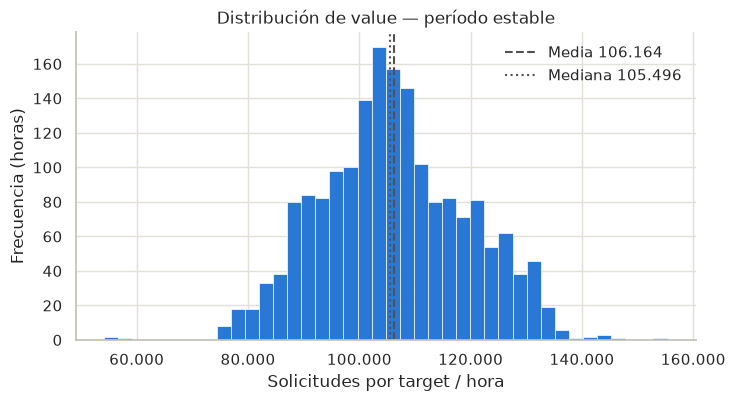

In [9]:
columna_numerica = "value"   # única variable numérica informativa del dataset

fig, ax = plt.subplots()
ax.hist(estable, bins=40, color=AZUL, edgecolor="white", linewidth=0.5)
ax.axvline(estable.mean(), color=TINTA, linestyle="--", linewidth=1.5, label=f"Media {valor_es(estable.mean())}")
ax.axvline(estable.median(), color=TINTA, linestyle=":", linewidth=1.5, label=f"Mediana {valor_es(estable.median())}")
ax.set_title(f"Distribución de {columna_numerica} — período estable")
ax.set_xlabel("Solicitudes por target / hora")
ax.set_ylabel("Frecuencia (horas)")
ax.xaxis.set_major_formatter(FORMATO_VALOR)
ax.legend(frameon=False)
plt.show()

### 3.c — Variables temporales derivadas: perfil por hora del día y por día de la semana
La plantilla original (tabla de frecuencias de una **categórica**) no aplica: las tres columnas categóricas son constantes, así que su tabla tendría una sola fila. En una serie temporal, las "categorías" útiles son las del **calendario**: hora del día (0–23) y día de la semana (lunes–domingo). Son variables ordinales y cíclicas. Para cada categoría no interesa contar filas, porque todas tienen la misma cantidad de horas, sino mirar el **valor medio de `value`**.

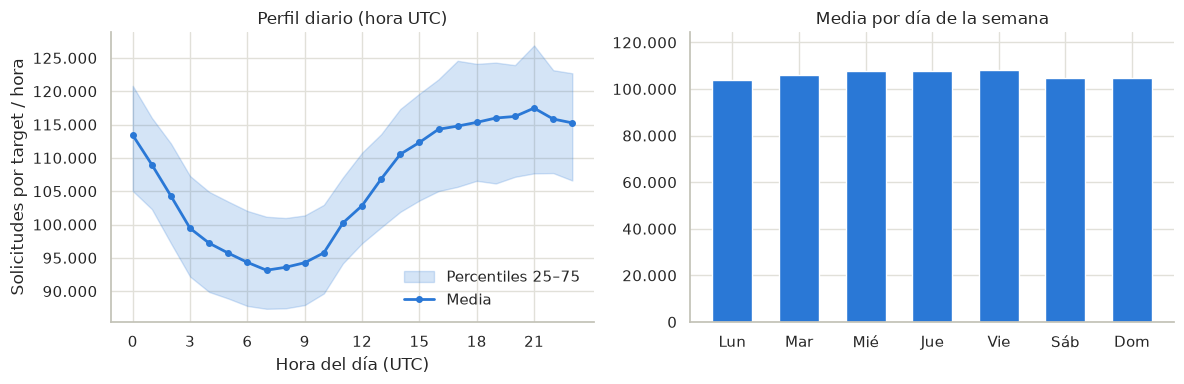

Hora de mínimo: 7 h UTC (93,145) | Hora de máximo: 21 h UTC (117,472) | Amplitud: 26%
Media por día: {'Lun': 103856, 'Mar': 105919, 'Mié': 107586, 'Jue': 107913, 'Vie': 108104, 'Sáb': 104866, 'Dom': 104775}
Diferencia entre el día más alto y el más bajo: 4.1%


In [10]:
dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
por_hora = estable.groupby(estable.index.hour)
media_hora = por_hora.mean()
p25_hora, p75_hora = por_hora.quantile(0.25), por_hora.quantile(0.75)
media_dia = estable.groupby(estable.index.day_of_week).mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.fill_between(media_hora.index, p25_hora, p75_hora, color=AZUL, alpha=0.2, label="Percentiles 25–75")
ax1.plot(media_hora.index, media_hora, color=AZUL, linewidth=2, marker="o", markersize=4, label="Media")
ax1.set_title("Perfil diario (hora UTC)")
ax1.set_xlabel("Hora del día (UTC)")
ax1.set_ylabel("Solicitudes por target / hora")
ax1.set_xticks(range(0, 24, 3))
ax1.yaxis.set_major_formatter(FORMATO_VALOR)
ax1.legend(frameon=False)

ax2.bar(dias, media_dia.values, color=AZUL, width=0.6)
ax2.set_title("Media por día de la semana")
ax2.set_ylim(0, media_dia.max() * 1.15)
ax2.yaxis.set_major_formatter(FORMATO_VALOR)
plt.tight_layout()
plt.show()

print(f"Hora de mínimo: {media_hora.idxmin()} h UTC ({media_hora.min():,.0f}) | "
      f"Hora de máximo: {media_hora.idxmax()} h UTC ({media_hora.max():,.0f}) | "
      f"Amplitud: {media_hora.max() / media_hora.min() - 1:.0%}")
print("Media por día:", {d: round(v) for d, v in zip(dias, media_dia.values)})
print(f"Diferencia entre el día más alto y el más bajo: {media_dia.max() / media_dia.min() - 1:.1%}")

### 3.d — Dependencia temporal: autocorrelación y mapa día × hora
La plantilla original (matriz de correlación entre variables numéricas) no aplica: hay **una sola** variable numérica, así que la matriz sería de 1×1. En una serie temporal, la pregunta equivalente es cuánto se parece la serie **a sí misma desplazada en el tiempo**: la **autocorrelación** en el rezago *k* es la correlación entre `value(t)` y `value(t−k)`. Los rezagos clave son 1 hora (inercia), 24 horas (ciclo diario) y 168 horas (ciclo semanal).

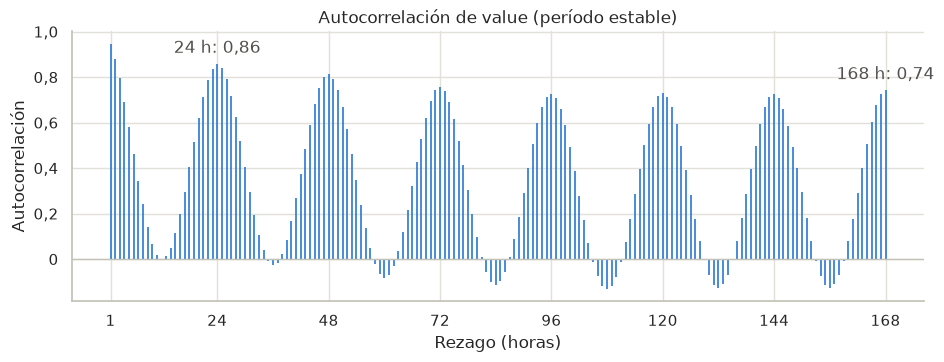

Autocorrelación en rezagos 1, 24 y 168: {1: 0.947, 24: 0.858, 168: 0.743}


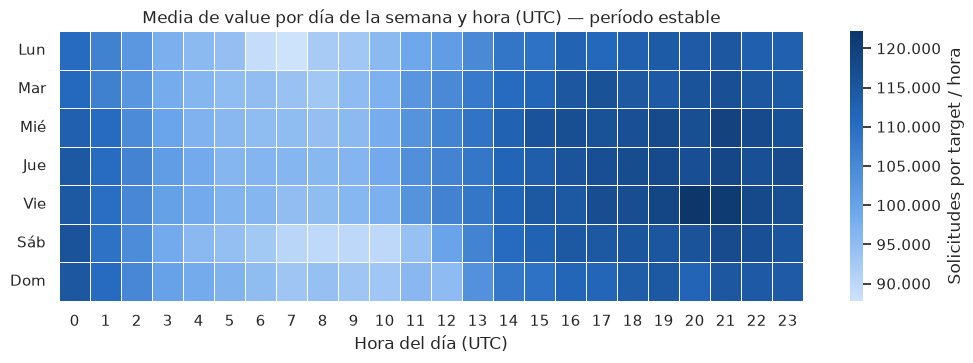

In [11]:
# Autocorrelación de la serie estable para rezagos de 1 a 168 horas
rezagos = range(1, 169)
acf = pd.Series([estable.autocorr(k) for k in rezagos], index=rezagos)

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.vlines(acf.index, 0, acf.values, color=AZUL, linewidth=1.2)
for k in (24, 168):
    ax.annotate(f"{k} h: {numero_es(acf[k], 2)}", (k, acf[k]), xytext=(0, 8), textcoords="offset points",
                ha="center", color=TINTA)
ax.axhline(0, color="#c3c2b7", linewidth=1)
ax.set_title("Autocorrelación de value (período estable)")
ax.set_xlabel("Rezago (horas)")
ax.set_ylabel("Autocorrelación")
ax.yaxis.set_major_formatter(EJE_ES)
ax.set_xticks([1, 24, 48, 72, 96, 120, 144, 168])
plt.show()
print("Autocorrelación en rezagos 1, 24 y 168:", {k: round(float(acf[k]), 3) for k in (1, 24, 168)})

# Mapa de calor: media de value por día de la semana (filas) y hora UTC (columnas)
from matplotlib.colors import LinearSegmentedColormap
azules = LinearSegmentedColormap.from_list("azules", ["#cde2fb", "#6da7ec", "#256abf", "#0d366b"])
tabla = (estable.to_frame("value")
         .assign(dia=estable.index.day_of_week, hora=estable.index.hour)
         .pivot_table(index="dia", columns="hora", values="value", aggfunc="mean"))
tabla.index = dias

fig, ax = plt.subplots(figsize=(12, 3.5))
sns.heatmap(tabla, cmap=azules, linewidths=0.5, linecolor="white",
            cbar_kws={"format": FORMATO_VALOR, "label": "Solicitudes por target / hora"}, ax=ax)
ax.set_title("Media de value por día de la semana y hora (UTC) — período estable")
ax.set_xlabel("Hora del día (UTC)")
ax.set_ylabel("")
ax.tick_params(axis="y", rotation=0)
plt.show()

### ¿Qué observar?

- En los **histogramas**: ¿la distribución es simétrica, sesgada, tiene varios picos? ¿Hay valores extremos (*outliers*)?
- En las **tablas de frecuencia**: ¿las categorías están balanceadas o hay una dominante?
- En la **correlación**: ¿hay pares de variables fuertemente relacionadas? ¿Eso tiene sentido en el dominio del problema?


### ✏️ Su respuesta — Etapa 3

**Hallazgos principales del EDA** (horas en UTC):

1. **La serie tiene tres regímenes y conviene analizarlos por separado.** Primero, 1264 horas sin tráfico (antes del 22/06 16:00). Después, 488 horas de puesta en marcha, en las que la media semanal pasa de 16 188 a 89 172. Desde el **13/07** hay operación estable, según el criterio del 90 % de la mediana semanal (umbral de 91 009). Esto se ve en la asimetría: con el período activo completo es **−1,76**, una cola izquierda causada por los ceros y la rampa; en el período estable es **0,11**, prácticamente simétrica.
2. **En operación estable, la carga es alta y relativamente concentrada.** Media de **106 164** y mediana de **105 496** solicitudes por target y hora, con un desvío de 13 286 (coeficiente de variación ≈ 12,5 %). La regla IQR marca solo **9 horas atípicas (0,5 %)**. La máxima es un pico de **155 381** el 04/09 a las 20 h; también hay caídas puntuales cercanas a 54 000 el 31/08 y el 06/09.
3. **La estacionalidad diaria es fuerte.** El mínimo está a las **7 h UTC (93 145)** y el máximo a las **21 h UTC (117 472)**, una amplitud del **26 %** dentro del mismo día. La carga sube de forma sostenida desde las 10 h UTC y se mantiene alta hasta la medianoche. Si los usuarios estuvieran en UTC−3, el valle caería a las 4 h locales y el pico a las 18 h locales.
4. **La estacionalidad semanal es débil.** Entre el día más bajo (lunes, 103 856) y el más alto (viernes, 108 104) hay solo un **4,1 %** de diferencia. El mapa de calor muestra que el patrón por hora se repite casi igual todos los días; los valles del sábado y del domingo a la mañana son algo más profundos.
5. **La serie depende mucho de su propio pasado y tiene tendencia.** La autocorrelación vale **0,947** a 1 hora, **0,858** a 24 horas y **0,743** a 168 horas (una semana). La media semanal subió de unos 98 000 en julio a **119 066** en la semana del 31/08 y después bajó a 104 515. Los valores recientes y los del mismo horario del día anterior son buenos predictores, pero el nivel cambia con el tiempo.

# Etapa 4 — Propuesta de modelo

A partir de lo que vieron, propongan **qué tipo de modelo** se podría construir con este dataset. La pregunta guía es: *¿qué tipo de problema de aprendizaje automático representan estos datos?*

| Si... | Entonces el tipo de modelo es... |
|---|---|
| Hay un **target categórico** (clase/etiqueta) | **Clasificación** |
| Hay un **target numérico continuo** | **Regresión** |
| **No hay target** y se buscan grupos | **Agrupamiento (*clustering*)** |
| Los datos son una **serie temporal** | **Pronóstico (*forecasting*)** |

> **No tienen que entrenar el modelo.** Solo deben **justificar** qué tipo correspondería y qué variable sería el *target* (si lo hubiera).


### Evidencia para la propuesta: líneas base ingenuas

Esto **no es entrenar un modelo**: no se ajusta ningún parámetro. Se mide qué tan bien se predeciría cada hora copiando un valor del pasado: el de 1 hora antes, el de 24 horas antes (misma hora del día anterior) y el de 168 horas antes (misma hora de la semana anterior). Sirve para dos cosas: medir cuánta información aporta cada rezago, y fijar el error que cualquier modelo propuesto tendría que superar.

- **MAE** (error absoluto medio): error típico en solicitudes por target y hora.
- **MAPE** (error porcentual absoluto medio): el mismo error expresado en porcentaje del valor real.

Se evalúan las dos últimas semanas completas de la serie.

In [12]:
# Período de evaluación: las dos últimas semanas completas (lunes a domingo)
eval_desde, eval_hasta = pd.Timestamp("2026-09-07", tz="UTC"), pd.Timestamp("2026-09-20 23:00", tz="UTC")
real = serie[eval_desde:eval_hasta]

filas = []
for rezago, nombre in [(1, "Hace 1 hora"), (24, "Misma hora, día anterior"), (168, "Misma hora, semana anterior")]:
    prediccion = serie.shift(rezago)[eval_desde:eval_hasta]
    error = (real - prediccion).abs()
    filas.append({"línea base": nombre, "rezago (h)": rezago,
                  "MAE": round(error.mean()), "MAPE (%)": round(100 * (error / real).mean(), 1)})

lineas_base = pd.DataFrame(filas).set_index("línea base")
print(f"Período evaluado: {eval_desde:%Y-%m-%d} a {eval_hasta:%Y-%m-%d} ({len(real)} horas)")
lineas_base

Período evaluado: 2026-09-07 a 2026-09-20 (336 horas)


,rezago (h),MAE,MAPE (%)
línea base,,,
Hace 1 hora,1,2961,2.7
"Misma hora, día anterior",24,6387,5.9
"Misma hora, semana anterior",168,9381,9.2


### ✏️ Su respuesta — Etapa 4

**Tipo de modelo propuesto:** **pronóstico de series temporales (*forecasting*)**, planteado como regresión sobre el tiempo: dado el historial hasta la hora *t*, predecir `value` en las horas *t+1 … t+h*, con horizonte de horas a pocos días.

**Variable objetivo (si aplica):** `value` (`RequestCountPerTarget`), es decir, las solicitudes promedio por target sano del *target group* en cada hora futura.

**Variables de entrada (features) que usarían:**
- **Calendario:** hora del día (0–23), día de la semana y si es fin de semana. Conviene codificar la hora de forma cíclica (seno/coseno), para que las 23 h y las 0 h queden cerca.
- **Rezagos de la propia serie:** `value` de hace 1 h, 24 h y 168 h.
- **Ventanas móviles:** media de las últimas 24 h y de los últimos 7 días, para capturar el nivel y la tendencia.
- Las columnas constantes (`load_balancer`, `target_group`, `metric_name`) y `period_end_utc` se descartan porque no aportan información.
- Solo se usan datos del período estable (desde el 13/07), para que la rampa de puesta en marcha no contamine el aprendizaje.

**Justificación:**
- **Por qué *forecasting*.** El target es **numérico continuo y ordenado en el tiempo**, y lo que se quiere es anticipar valores futuros. No es **clasificación**, porque no hay clases que predecir, ni **clustering**, porque no buscamos grupos de observaciones sino el comportamiento futuro de una única serie.
- **Por qué esas *features*.** El EDA mostró que la serie depende mucho de su pasado: autocorrelación de 0,947 a 1 h, 0,858 a 24 h y 0,743 a 168 h. También mostró una estacionalidad diaria fuerte, con una amplitud del 26 % entre las 7 h y las 21 h UTC. Eso justifica los rezagos y las variables de hora.
- **Qué dicen las líneas base.** Copiar el valor de hace 24 h da un **MAPE de 5,9 %**, y copiar el de hace 168 h da **9,2 %**: el ciclo semanal aporta menos que el diario, en línea con la débil diferencia del 4,1 % entre días. El rezago de 1 h logra un 2,7 %, pero solo sirve para pronosticar una hora hacia adelante, lo que no alcanza para planificar.
- **Meta concreta.** Un modelo que combine estacionalidad diaria y nivel reciente debería bajar de ese **5,9 %** con un horizonte de 24 h.
- **Modelos candidatos.** Un regresor de *gradient boosting* sobre las *features* anteriores es simple y explicable. Como alternativas clásicas de series de tiempo están SARIMA, con estacionalidad de 24, o Prophet.

# Etapa 5 — Uso previsto

Por último, pongan el modelo en contexto. Un modelo no se construye en el vacío: sirve para **ayudar a tomar una decisión**.


### ✏️ Su respuesta — Etapa 5

**¿Para qué se usaría el modelo?** Para **anticipar la carga del servicio de tienda** con horas o días de anticipación, de modo que la capacidad (cantidad de targets del *target group* detrás del balanceador) esté lista **antes** de que llegue el pico y no después. Hoy el escalado automático reacciona cuando la carga ya subió. Con un pronóstico, se puede escalar de forma preventiva antes de la subida que empieza alrededor de las 10 h UTC y reducir capacidad durante el valle de las 7 h UTC.

**¿Quién lo usaría?** El equipo de **infraestructura / SRE (DevOps)** que opera el servicio en producción. En segundo lugar, el área que controla los **costos de nube**, porque la cantidad de targets encendidos es el costo principal del servicio.

**¿Qué decisión ayudaría a tomar?**
- **Escalado programado.** Configurar acciones programadas de *autoscaling* para subir el mínimo de targets antes del pico diario y bajarlo de madrugada. Por ejemplo, si para mañana a las 21 h UTC se pronostica un 26 % más de carga que en el valle, se agregan targets a partir de las 10–12 h UTC.
- **Alertas de anomalía.** Una hora que se aleje mucho del pronóstico, como las caídas del 31/08 y el 06/09 o el pico de 155 381 del 04/09, puede indicar un incidente, un error de despliegue o un evento comercial, y vale la pena alertar.
- **Planificación de capacidad y presupuesto.** La tendencia de agosto–septiembre, con la media semanal subiendo de unos 98 000 a 119 066, sirve para estimar cuántos targets harán falta el mes siguiente.

**Riesgos o consideraciones éticas:**
- **La métrica depende de la cantidad de targets sanos.** Según AWS, `RequestCountPerTarget` es el total de solicitudes del *target group* dividido por la cantidad de **targets sanos**. Si el *autoscaling* agrega targets, el valor baja aunque el tráfico total sea el mismo. Si un target falla los *health checks*, el valor sube sin que haya más tráfico. Un modelo que decide cuántos targets poner a partir de una métrica que esos mismos targets modifican crea un **circuito de retroalimentación**. Antes de usarlo en producción convendría pronosticar el **tráfico total** (`RequestCount` con dimensión `LoadBalancer, TargetGroup`, estadístico `Sum`) y derivar de ahí los targets necesarios.
- **Historia corta y cambio de régimen.** Solo hay unos 2,5 meses de operación estable (1823 horas) y el nivel cambió dentro de ese período. El modelo no vio eventos estacionales anuales, como fechas comerciales o feriados, y podría subestimar picos excepcionales.
- **Costo asimétrico del error.** Subestimar la carga provoca lentitud o caídas que afectan a los clientes; sobreestimarla solo cuesta dinero. El escalado basado en el pronóstico debería tener un **margen de seguridad** y mantener el *autoscaling* reactivo como red de respaldo.
- **Datos sensibles.** El dataset no contiene datos personales, solo conteos agregados. Sí incluye identificadores internos de la infraestructura de producción (nombres del balanceador y del *target group*), que conviene no publicar fuera del ámbito académico.

# Declaración de uso de IA

Este notebook se desarrolló con asistencia de un agente de inteligencia artificial, bajo la dirección del estudiante.

| Aspecto | Detalle |
|---|---|
| **Herramienta** | Claude Code (agente de Anthropic que opera desde la terminal) |
| **Modelo** | Claude Opus 5.5 (`claude-opus-5-5`) |
| **Marco de trabajo** | Desarrollo guiado por especificaciones (*Spec-Driven Development*, SDD) con **OpenSpec 2.0.0** (`@fission-ai/openspec`), esquema `spec-driven` |
| **Entorno reproducible** | `uv` (Python 3.12, dependencias fijadas en `uv.lock`) |
| **Fecha** | 16/11/2026 |

**Cómo se trabajó.** Cada parte del trabajo se planteó como un *cambio* de OpenSpec con cuatro artefactos: propuesta (por qué), especificación (qué debe cumplirse, con escenarios verificables), diseño (cómo y con qué criterio) y tareas (pasos, cada uno con su verificación). El estudiante aprobó cada cambio antes de implementarlo. Al cerrarse, cada cambio se archivó y sus requisitos se consolidaron en `openspec/specs/`. Los cambios completos, con sus decisiones y criterios, están en `openspec/changes/archive/`.

**Cambios que afectan a este notebook:**
- `setup-uv-environment`: entorno de Python con `uv`.
- `load-store-traffic-dataset`: Etapa 1.
- `identify-store-traffic-data-types`: Etapa 2.
- `explore-store-traffic-series`: Etapa 3.
- `propose-store-traffic-model`: Etapa 4.
- `define-store-traffic-model-use`: Etapa 5 y cierre.
- `clarify-request-count-per-target`: precisión de la unidad de la métrica (por target, no por instancia).
- `format-chart-numbers-and-ai-declaration`: formato de números en los gráficos y esta declaración.

**Qué hizo el agente:** escribió el código de las celdas, ejecutó el notebook, redactó las respuestas a partir de las salidas ejecutadas y redactó los artefactos de OpenSpec. Las cifras de las respuestas se verificaron contra las salidas del propio notebook, y la definición de las métricas, contra la documentación de AWS.

**Qué hizo el estudiante:** eligió y aportó los datos; definió el flujo de trabajo (OpenSpec, un cambio por etapa, `uv`) y las restricciones del proyecto (artefactos en español, decisiones respaldadas por criterios y datos, pasos reproducibles); cuestionó la interpretación de la métrica `RequestCountPerTarget`; pidió la variante con `RequestCount` y los ajustes de presentación; y aprobó cada cambio.

# Cierre y entrega

Antes de entregar, verifiquen que:

- [x] Eligieron un dataset y lo cargaron correctamente (Etapa 1).
- [x] Identificaron y clasificaron los tipos de datos (Etapa 2).
- [x] Ejecutaron el EDA con las herramientas adecuadas al tipo de datos (Etapa 3).
- [x] Propusieron y justificaron un tipo de modelo (Etapa 4).
- [x] Explicaron el uso previsto y sus consideraciones (Etapa 5).
- [x] **Todas las celdas están ejecutadas** y sus salidas son visibles.

**Para entregar:** `Archivo → Descargar → Descargar .ipynb`, o compartan el enlace de Colab con permiso de lectura.

---

*Fundamentos de Aprendizaje Automático · 2026 · Universidad Austral*
